In [10]:
!nvidia-smi


Wed Nov 12 19:39:58 2025       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 581.29                 Driver Version: 581.29         CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                  Driver-Model | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA GeForce GTX 1650 Ti   WDDM  |   00000000:01:00.0 Off |                  N/A |
| N/A   52C    P8              1W /   50W |     349MiB /   4096MiB |     28%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [11]:
# Cell 1
import os
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, random_split, WeightedRandomSampler
from torchvision import datasets, transforms, models
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm.notebook import tqdm
from sklearn.metrics import classification_report, confusion_matrix, roc_curve, auc
from sklearn.preprocessing import label_binarize
from itertools import cycle

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)
torch.cuda.empty_cache()


Using device: cuda


Classes found: ['Mild Dementia', 'Moderate Dementia', 'Non Demented', 'Very mild Dementia']
Total images: 86437


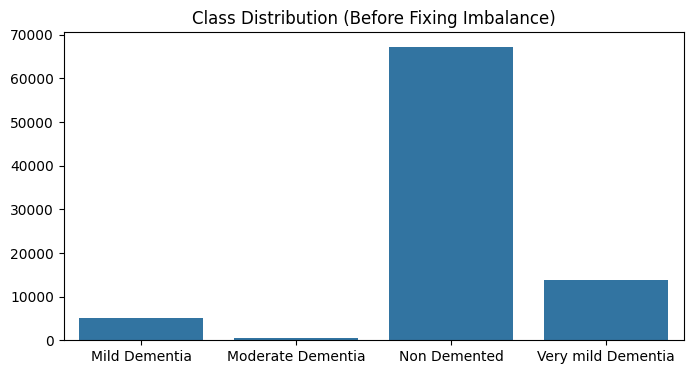

In [12]:
# Cell 2
datasetPath = r"C:\Users\sanja\Desktop\MRI_Project\AD_DATASET\Data"
classes = os.listdir(datasetPath)
print("Classes found:", classes)

# Define transform for EDA and training
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
])

# Load dataset
full_dataset = datasets.ImageFolder(root=datasetPath, transform=transform)

# Show dataset size
print("Total images:", len(full_dataset))

# Compute class distribution
class_counts = [0]*len(classes)
for _, label in full_dataset.samples:
    class_counts[label] += 1

plt.figure(figsize=(8,4))
sns.barplot(x=classes, y=class_counts)
plt.title("Class Distribution (Before Fixing Imbalance)")
plt.show()


Exception ignored in: <function tqdm.__del__ at 0x000001AA751D76D0>
Traceback (most recent call last):
  File "C:\Users\sanja\anaconda3\envs\gpu_env\lib\site-packages\tqdm\std.py", line 1148, in __del__
    self.close()
  File "C:\Users\sanja\anaconda3\envs\gpu_env\lib\site-packages\tqdm\notebook.py", line 279, in close
    self.disp(bar_style='danger', check_delay=False)
AttributeError: 'tqdm_notebook' object has no attribute 'disp'


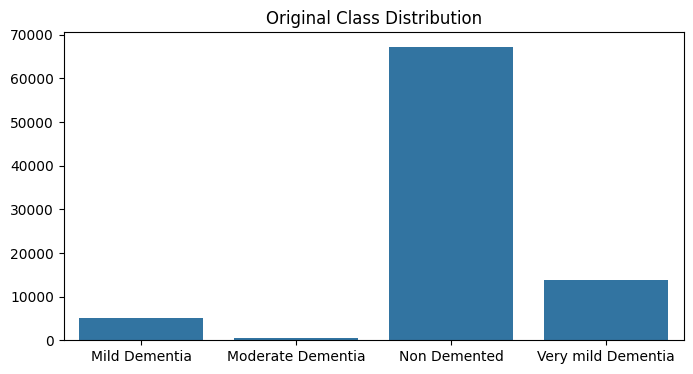

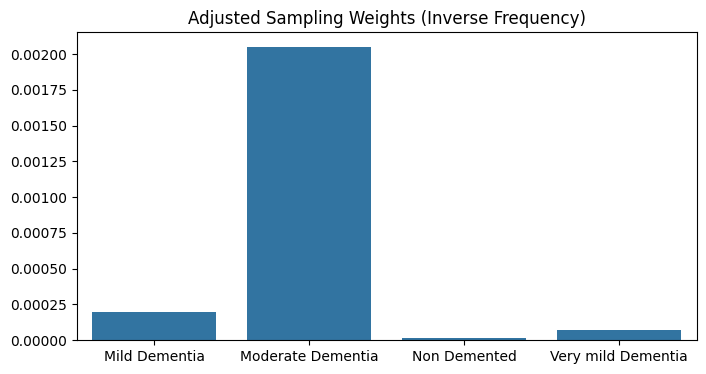

In [13]:
# Cell 3
class_counts = torch.tensor(class_counts, dtype=torch.float)
class_weights = 1. / class_counts
sample_weights = [class_weights[label] for _, label in full_dataset.samples]

sampler = WeightedRandomSampler(sample_weights, num_samples=len(sample_weights), replacement=True)

plt.figure(figsize=(8,4))
sns.barplot(x=classes, y=class_counts.cpu().numpy())
plt.title("Original Class Distribution")
plt.show()

plt.figure(figsize=(8,4))
sns.barplot(x=classes, y=(1/class_counts).cpu().numpy())
plt.title("Adjusted Sampling Weights (Inverse Frequency)")
plt.show()


✅ Dataset split complete:
Train: 60505, Val: 12965, Test: 12967


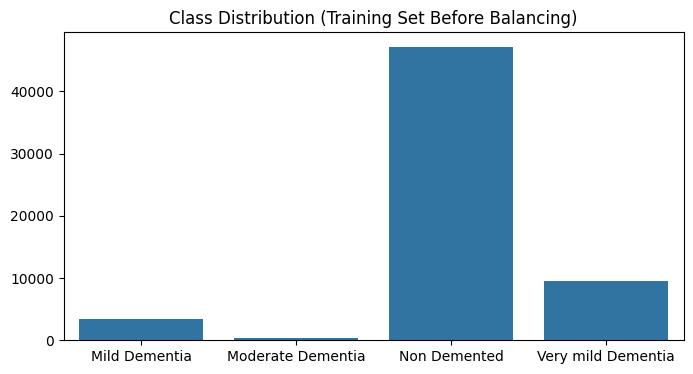

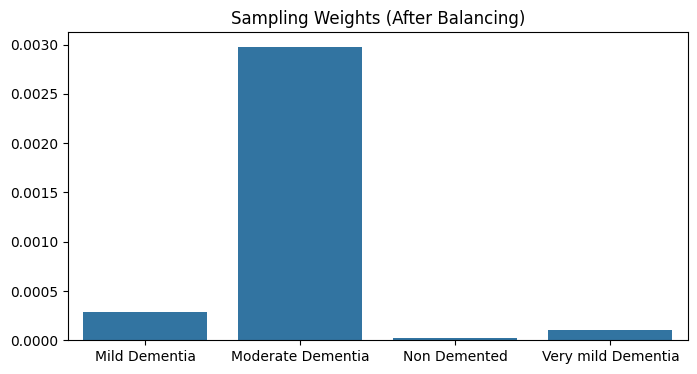

In [14]:
# Cell 4 (Revised & Corrected)
from torch.utils.data import DataLoader, WeightedRandomSampler
import matplotlib.pyplot as plt
import seaborn as sns
import torch

# --- Split dataset (70/15/15)
train_len = int(0.7 * len(full_dataset))
val_len = int(0.15 * len(full_dataset))
test_len = len(full_dataset) - train_len - val_len

train_set, val_set, test_set = random_split(full_dataset, [train_len, val_len, test_len])

# --- Apply data augmentation for training, basic transforms for val/test
augment_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.ColorJitter(brightness=0.1, contrast=0.1),
    transforms.ToTensor(),
])

train_set.dataset.transform = augment_transform
val_set.dataset.transform = transform
test_set.dataset.transform = transform

# --- Compute class counts in training subset
train_labels = [label for _, label in train_set]
class_counts = torch.bincount(torch.tensor(train_labels))
class_weights = 1. / class_counts.float()

# --- Create sample weights for WeightedRandomSampler
sample_weights = [class_weights[label] for label in train_labels]
sampler = WeightedRandomSampler(
    weights=sample_weights,
    num_samples=len(sample_weights),
    replacement=True
)

# --- DataLoaders
train_loader = DataLoader(train_set, batch_size=32, sampler=sampler, num_workers=2, pin_memory=True)
val_loader = DataLoader(val_set, batch_size=32, shuffle=False, num_workers=2)
test_loader = DataLoader(test_set, batch_size=32, shuffle=False, num_workers=2)

print(f"✅ Dataset split complete:")
print(f"Train: {len(train_set)}, Val: {len(val_set)}, Test: {len(test_set)}")

# --- Visualize Class Balance (Before vs After)
plt.figure(figsize=(8,4))
sns.barplot(x=[cls for cls in classes], y=class_counts.numpy())
plt.title("Class Distribution (Training Set Before Balancing)")
plt.show()

plt.figure(figsize=(8,4))
sns.barplot(x=[cls for cls in classes], y=(1/class_counts.float()).numpy())
plt.title("Sampling Weights (After Balancing)")
plt.show()


In [15]:
# Cell 6
model = models.resnet50(weights=models.ResNet50_Weights.IMAGENET1K_V1)
for param in model.parameters():
    param.requires_grad = False

# Replace final layer
model.fc = nn.Sequential(
    nn.Dropout(0.3),
    nn.Linear(model.fc.in_features, 4)
)
model = model.to(device)

print(model)


ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): Bottleneck(
      (conv1): Conv2d(64, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (conv3): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (bn3): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (downsample): Sequential(
        (0): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 

In [16]:
# Cell 7
from torch.optim.lr_scheduler import ReduceLROnPlateau

criterion = nn.CrossEntropyLoss()
optimizer = optim.AdamW(model.parameters(), lr=1e-4, weight_decay=1e-4)
scheduler = ReduceLROnPlateau(optimizer, mode='min', patience=3, factor=0.5)

# Early stopping parameters
best_val_loss = np.inf
patience = 7
trigger_times = 0
save_path = "best_resnet50_mri.pth"


In [17]:
# Cell 8
from tqdm import tqdm

num_epochs = 30
train_acc_list, val_acc_list = [], []

for epoch in range(num_epochs):
    model.train()
    train_loss, correct, total = 0, 0, 0
    
    loop = tqdm(train_loader, total=len(train_loader), desc=f"Epoch [{epoch+1}/{num_epochs}]")
    for images, labels in loop:
        images, labels = images.to(device), labels.to(device)
        
        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        
        train_loss += loss.item()
        _, preds = torch.max(outputs, 1)
        correct += (preds == labels).sum().item()
        total += labels.size(0)
        
        loop.set_postfix(loss=loss.item())
    
    train_acc = 100 * correct / total
    val_loss, val_correct, val_total = 0, 0, 0
    model.eval()
    with torch.no_grad():
        for images, labels in val_loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            loss = criterion(outputs, labels)
            val_loss += loss.item()
            _, preds = torch.max(outputs, 1)
            val_correct += (preds == labels).sum().item()
            val_total += labels.size(0)
    val_acc = 100 * val_correct / val_total

    scheduler.step(val_loss)
    train_acc_list.append(train_acc)
    val_acc_list.append(val_acc)

    print(f"Epoch {epoch+1}: Train Acc={train_acc:.2f}% | Val Acc={val_acc:.2f}%")

    # Early stopping
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        trigger_times = 0
        torch.save(model.state_dict(), save_path)
    else:
        trigger_times += 1
        if trigger_times >= patience:
            print("Early stopping triggered.")
            break


Epoch [1/30]: 100%|██████████| 1891/1891 [05:03<00:00,  6.24it/s, loss=0.818]


Epoch 1: Train Acc=57.52% | Val Acc=69.99%


Epoch [2/30]: 100%|██████████| 1891/1891 [05:04<00:00,  6.21it/s, loss=0.732]


Epoch 2: Train Acc=66.59% | Val Acc=68.79%


Epoch [3/30]: 100%|██████████| 1891/1891 [05:04<00:00,  6.21it/s, loss=0.693]


...

Epoch 15: Train Acc=72.01% | Val Acc=73.57%


Epoch [16/30]: 100%|██████████| 1891/1891 [05:06<00:00,  6.17it/s, loss=0.765]


Epoch 16: Train Acc=71.85% | Val Acc=72.22%


Epoch [17/30]: 100%|██████████| 1891/1891 [05:10<00:00,  6.09it/s, loss=0.683]


Epoch 17: Train Acc=71.55% | Val Acc=72.16%
Early stopping triggered.


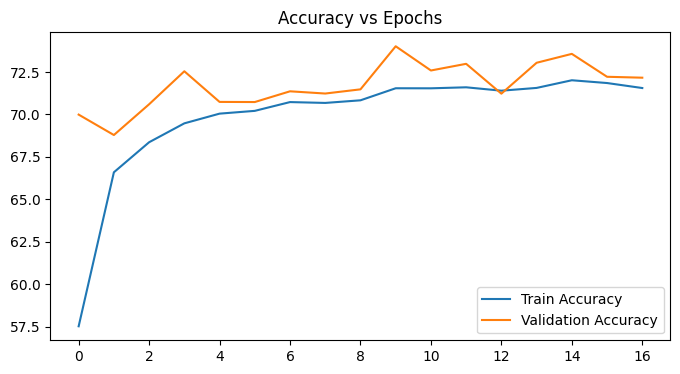

In [18]:
# Cell 9
plt.figure(figsize=(8,4))
plt.plot(train_acc_list, label='Train Accuracy')
plt.plot(val_acc_list, label='Validation Accuracy')
plt.title('Accuracy vs Epochs')
plt.legend()
plt.show()


100%|██████████| 406/406 [01:43<00:00,  3.92it/s]


                    precision    recall  f1-score   support

     Mild Dementia       0.31      0.75      0.43       747
 Moderate Dementia       0.20      0.91      0.33        82
      Non Demented       0.94      0.79      0.86     10043
Very mild Dementia       0.49      0.56      0.52      2095

          accuracy                           0.75     12967
         macro avg       0.48      0.75      0.53     12967
      weighted avg       0.83      0.75      0.78     12967



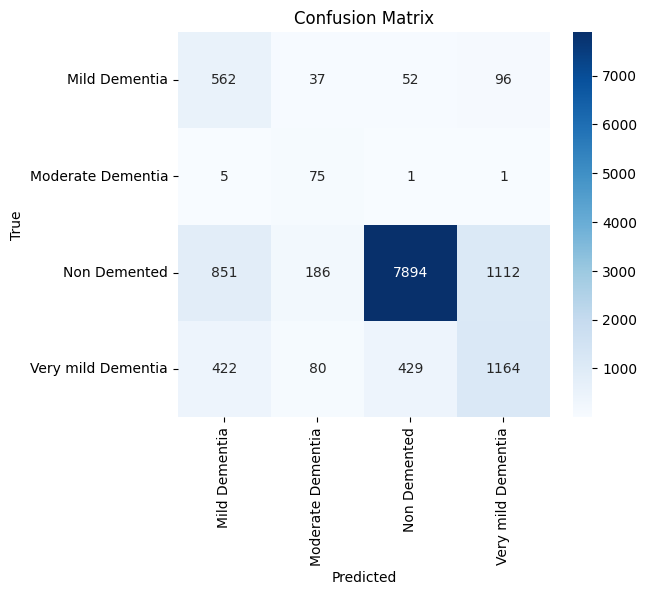

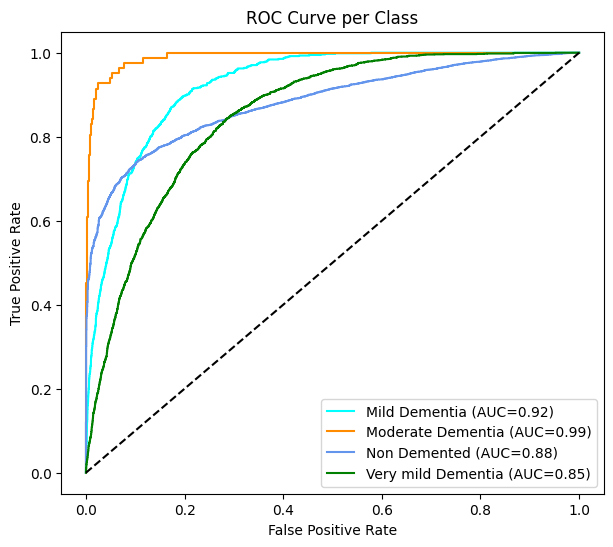

In [19]:
# Cell 10
model.load_state_dict(torch.load(save_path))
model.eval()

all_preds, all_labels, all_probs = [], [], []

with torch.no_grad():
    for images, labels in tqdm(test_loader):
        images = images.to(device)
        outputs = model(images)
        probs = torch.softmax(outputs, dim=1)
        _, preds = torch.max(probs, 1)
        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.numpy())
        all_probs.extend(probs.cpu().numpy())

# Classification report
print(classification_report(all_labels, all_preds, target_names=classes))

# Confusion matrix
cm = confusion_matrix(all_labels, all_preds)
plt.figure(figsize=(6,5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=classes, yticklabels=classes)
plt.title('Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('True')
plt.show()

# ROC Curve
y_true_bin = label_binarize(all_labels, classes=list(range(len(classes))))
fpr, tpr, roc_auc = dict(), dict(), dict()
for i in range(len(classes)):
    fpr[i], tpr[i], _ = roc_curve(y_true_bin[:, i], np.array(all_probs)[:, i])
    roc_auc[i] = auc(fpr[i], tpr[i])

plt.figure(figsize=(7,6))
for i, color in zip(range(len(classes)), cycle(['aqua','darkorange','cornflowerblue','green'])):
    plt.plot(fpr[i], tpr[i], color=color, label=f'{classes[i]} (AUC={roc_auc[i]:.2f})')
plt.plot([0,1],[0,1],'k--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve per Class')
plt.legend()
plt.show()


In [20]:
# Cell 11
test_correct = np.sum(np.array(all_preds) == np.array(all_labels))
test_acc = 100 * test_correct / len(all_labels)
print(f"Final Test Accuracy: {test_acc:.2f}%")


Final Test Accuracy: 74.77%
